# Program 11: the request stream

**What:** generate random sequences of learn and unlearn requests, such as `L3 → L0 → U3 → L9 → U0 …`.

**How:** a function `make_stream(n_tasks, n_requests, seed, level)` returns a list of `("L", id)` or `("U", id)`. Rules: you can only unlearn something already learned, and a forgotten item is never relearned. Support `level="task"` (forget a whole task) and `level="class"` (forget one class). Save streams to JSON so every method runs on identical sequences.

**Why:** this *is* the CLU setting. Fixed, saved streams make comparisons fair.

**Understanding note:** order matters. Forgetting something early and then learning many similar tasks is the worst case for relapse.

**Done when:** you can generate, save and reload streams of 15, 30 and 100 requests.

This program trains nothing. It runs in seconds, on the CPU.

## Where this fits (for a first-time reader)

| Phase | Programs | Setting |
|---|---|---|
| B: continual learning | 03–06 | Split CIFAR-100: 10 tasks of 10 classes arrive one after another. DER++ (06) was the best learner. |
| C: offline unlearning | 07–10 | CIFAR-10: one finished model, one forget request ("forget cat"). BadTeacher (09) was the best, but MIA (10) still found a trace. |
| **D: CLU** | **11–15** | **both at once:** learn requests and forget requests arrive mixed, in one stream |

That last row is **Continual Learning-Unlearning (CLU)**, the setting of the UnCLe paper and of our method. A real system receives requests over time, for example:

```
L3 → L0 → U3 → L9 → U0 → L5 ...
learn task 3, learn task 0, forget task 3, learn task 9, forget task 0, learn task 5, ...
```

The question for Phase D: after `U3`, does task 3 stay forgotten while tasks 9 and 5 are learned, or does it come back (**relapse**)?

This program only **writes the streams down**. Program 12 runs DER++ + BadTeacher on them. All methods (baselines and ours) must see **exactly the same streams**, so we generate them once, save them as JSON files and always load them from those files.

The code lives in `common/stream.py`, so programs 12–20 can import it.

## 1. Setup

- `n_tasks`: 10, the Split CIFAR-100 tasks from Phase B.
- `seeds`: every stream is saved for 3 seeds. A result is only trusted if it holds on all three.
- `standard`: the streams to generate (section 4 explains the choice).

In [1]:
import pickle, sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.stream
for module in (common.utils, common.stream):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np

from common.stream import (check_stream, learning_after_forget, load_stream, make_stream,
                           max_requests, save_stream, stream_to_str, task_of)
from common.utils import DATA_DIR, RESULTS_DIR, log_run

SETTINGS = {
    "n_tasks": 10,
    "classes_per_task": 10,
    "seeds": [0, 1, 2],
    "data_seed": 0,       # the class order of Split CIFAR-100 (SplitCIFAR100(seed=0)), only used for names
    "standard": [         # (level, number of requests)
        ("task", 15),
        ("task", 20),
        ("class", 30),
        ("class", 100),
    ],
}
STREAM_DIR = RESULTS_DIR / "streams"
N_TASKS = SETTINGS["n_tasks"]

# Class names in our label order, read from CIFAR-100's small "meta" file (no images loaded).
# Label c of Split CIFAR-100 is original class class_order[c] (see common/data.py).
class_order = np.random.RandomState(SETTINGS["data_seed"]).permutation(100)
meta_path = DATA_DIR / "cifar-100-python" / "meta"
if meta_path.exists():
    with open(meta_path, "rb") as f:
        fine_names = pickle.load(f, encoding="latin1")["fine_label_names"]
    NAMES = [fine_names[c] for c in class_order]
else:
    NAMES = [f"class {c}" for c in range(100)]
for t in range(N_TASKS):
    print(f"task {t}: " + ", ".join(NAMES[t * 10:(t + 1) * 10]))

task 0: crab, telephone, baby, otter, skunk, turtle, can, shark, orchid, whale
task 1: orange, tulip, snake, bus, beetle, dolphin, clock, cockroach, forest, bicycle
task 2: lion, poppy, bear, sea, lobster, motorcycle, bee, worm, sunflower, skyscraper
task 3: plain, squirrel, train, road, mushroom, crocodile, caterpillar, palm_tree, porcupine, shrew
task 4: aquarium_fish, plate, leopard, lawn_mower, beaver, camel, castle, lamp, kangaroo, bed
task 5: trout, pine_tree, apple, fox, cup, mouse, boy, girl, cloud, oak_tree
task 6: bowl, elephant, raccoon, pear, spider, tank, flatfish, table, butterfly, tractor
task 7: cattle, dinosaur, mountain, wolf, woman, rocket, chair, wardrobe, seal, snail
task 8: couch, house, streetcar, man, keyboard, rabbit, pickup_truck, bridge, tiger, rose
task 9: television, hamster, chimpanzee, sweet_pepper, bottle, willow_tree, ray, possum, maple_tree, lizard


## 2. The rules, and one example

A request is a pair:
- `("L", t)`: **learn task t**, all 10 of its classes. In program 12 this means training on the task with DER++.
- `("U", i)`: **unlearn item i**. With `level="task"`, i is a task id and the whole task is forgotten. With `level="class"`, i is a class label (0–99) and only that one class is forgotten.

Learning is always by task, even at class level, because continual learners train on one task at a time. Only the forgetting gets finer.

Three rules:
1. every task is learned **exactly once**;
2. you can only unlearn something that **has been learned** and **not forgotten yet**;
3. a forgotten item is **never learned again**. This follows from rule 1, but it matters: if a forgotten task's accuracy comes back later, it was not retrained. That is relapse.

How `make_stream` builds a random stream:
1. take 10 `L` markers and `n_requests − 10` `U` markers and shuffle them, until no `U` comes before there is anything to forget;
2. give the `L`s the tasks in a random order;
3. give each `U` a random item from what is currently known.

Same seed → same stream, always.

In [2]:
example = make_stream(N_TASKS, 15, seed=0, level="task")
print(stream_to_str(example))
print("\nrules respected:", check_stream(example, N_TASKS, "task"))
print("same seed gives the same stream:", example == make_stream(N_TASKS, 15, seed=0, level="task"))
print("another seed gives another stream:", example != make_stream(N_TASKS, 15, seed=1, level="task"))

# The same at class level: the U ids are now class labels.
example_cls = make_stream(N_TASKS, 30, seed=0, level="class")
print("\nclass level, 30 requests:")
print(" → ".join(f"L{i}" if k == "L" else f"U{i} ({NAMES[i]})" for k, i in example_cls))

L5 → L2 → L3 → L4 → U5 → L9 → L0 → U3 → U2 → L8 → U8 → L7 → L6 → L1 → U4

rules respected: True
same seed gives the same stream: True
another seed gives another stream: True

class level, 30 requests:
L6 → U60 (bowl) → U62 (raccoon) → U63 (pear) → U64 (spider) → U61 (elephant) → U67 (table) → U65 (tank) → U69 (tractor) → U68 (butterfly) → L4 → U41 (plate) → L8 → U42 (leopard) → U66 (flatfish) → U40 (aquarium_fish) → L5 → U47 (lamp) → L7 → L1 → U49 (bed) → U13 (bus) → L9 → L3 → U16 (clock) → L2 → L0 → U52 (apple) → U7 (shark) → U48 (kangaroo)


## 3. The checker catches broken streams

`check_stream` is run on every stream that is made **and** every stream that is loaded, so a hand-edited JSON file with a mistake is caught before any training starts. Each broken stream below should be rejected with a clear message.

In [3]:
broken = {
    "forget before learning": [("U", 3), ("L", 3)],
    "learn a task twice": [("L", 3), ("L", 0), ("L", 3)],
    "forget twice": [("L", 3), ("U", 3), ("U", 3)],
    "relearn a forgotten task": [("L", 3), ("U", 3), ("L", 3)],
}
for name, stream in broken.items():
    try:
        check_stream(stream, N_TASKS, "task")
        print(f"{name:>26}: NOT caught (this is a bug)")
    except ValueError as err:
        print(f"{name:>26}: caught -> {err}")

# Class level: forgetting a class of a task that was not learned yet.
try:
    check_stream([("L", 0), ("U", 15)], N_TASKS, "class")
except ValueError as err:
    print(f"{'class of an unlearned task':>26}: caught -> {err}")

    forget before learning: caught -> request 0: U3: not learned yet, so it cannot be unlearned
        learn a task twice: caught -> request 2: L3: task 3 was already learned (each task is learned once)
              forget twice: caught -> request 2: U3: already forgotten
  relearn a forgotten task: caught -> request 2: L3: task 3 was already learned (each task is learned once)
class of an unlearned task: caught -> request 1: U15: not learned yet, so it cannot be unlearned


## 4. How long can a stream be?

Because each task is learned once and each item is forgotten at most once:

| level | longest stream with 10 tasks | why |
|---|---|---|
| task | 10 L + 10 U = **20** | only 10 tasks to forget |
| class | 10 L + 100 U = **110** | 100 classes to forget |

So the roadmap's **30 and 100 request streams only exist at class level.** We save:

| stream | learn | forget | what it tests |
|---|---|---|---|
| `task15` | 10 tasks | 5 whole tasks | the main setting (like UnCLe): half the tasks forgotten |
| `task20` | 10 tasks | all 10 tasks | the extreme: everything is forgotten at some point |
| `class30` | 10 tasks | 20 single classes | class-level forgetting, our method's target |
| `class100` | 10 tasks | 90 single classes | stress test: many small forget steps, only 10 classes survive |

Each one is saved for seeds 0, 1 and 2, so 12 files in `results/streams/`.

In [4]:
for level in ("task", "class"):
    print(f"longest {level}-level stream with {N_TASKS} tasks: {max_requests(N_TASKS, level)} requests")
try:
    make_stream(N_TASKS, 30, seed=0, level="task")
except ValueError as err:
    print("\nasking for 30 task-level requests ->", err)

longest task-level stream with 10 tasks: 20 requests
longest class-level stream with 10 tasks: 110 requests

asking for 30 task-level requests -> with 10 tasks at level 'task', n_requests must be between 10 (learn only) and 20 (forget everything); got 30


## 5. Generate and save the standard streams

File names: `{level}{n_requests}_seed{seed}.json`, for example `results/streams/task15_seed0.json`. Each file holds the settings and the list of requests, so it can be read by eye.

In [5]:
saved = {}
for level, n in SETTINGS["standard"]:
    for seed in SETTINGS["seeds"]:
        stream = make_stream(N_TASKS, n, seed=seed, level=level)
        path = STREAM_DIR / f"{level}{n}_seed{seed}.json"
        save_stream(stream, path, n_tasks=N_TASKS, level=level, seed=seed)
        saved[path.name] = stream

for name, stream in saved.items():
    text = stream_to_str(stream)
    print(f"{name:>22}: {text if len(text) < 110 else text[:107] + '...'}")
print("\nsaved", len(saved), "files to", STREAM_DIR)
print("example file content:\n", (STREAM_DIR / "task15_seed0.json").read_text()[:300], "...")

     task15_seed0.json: L5 → L2 → L3 → L4 → U5 → L9 → L0 → U3 → U2 → L8 → U8 → L7 → L6 → L1 → U4
     task15_seed1.json: L8 → L1 → L0 → L7 → U0 → L6 → L3 → U7 → L9 → U9 → L2 → L5 → U1 → U6 → L4
     task15_seed2.json: L1 → L6 → L5 → U5 → U1 → L4 → L2 → L7 → L8 → U6 → L0 → U7 → L3 → L9 → U3
     task20_seed0.json: L2 → U2 → L9 → L7 → L1 → U1 → L8 → U9 → L3 → L5 → U8 → U7 → U3 → U5 → L0 → U0 → L6 → L4 → U4 → U6
     task20_seed1.json: L8 → U8 → L6 → U6 → L7 → U7 → L9 → L5 → L0 → L3 → U0 → L4 → L2 → U2 → U3 → L1 → U4 → U9 → U1 → U5
     task20_seed2.json: L6 → L8 → U8 → U6 → L2 → L7 → L4 → U7 → L9 → L0 → U0 → U9 → L3 → U2 → U4 → L5 → U3 → L1 → U5 → U1
    class30_seed0.json: L6 → U60 → U62 → U63 → U64 → U61 → U67 → U65 → U69 → U68 → L4 → U41 → L8 → U42 → U66 → U40 → L5 → U47 → L7 ...
    class30_seed1.json: L8 → L4 → U41 → L6 → U81 → U60 → U80 → L9 → U90 → L7 → U64 → U96 → L3 → L1 → U76 → U82 → U68 → U73 → U13 → ...
    class30_seed2.json: L7 → L6 → U64 → L2 → U62 → U20 → U74 → L9 → L8 → 

## 6. Reload and compare (the "Done when" check)

Every file is loaded back (which runs the checker again) and compared with the stream that was saved. They must be identical.

In [6]:
all_ok = True
for name, stream in saved.items():
    info = load_stream(STREAM_DIR / name)
    same = info["requests"] == stream
    all_ok &= same
    n_l = sum(k == "L" for k, _ in info["requests"])
    print(f"{name:>22}: {info['n_requests']:3d} requests ({n_l} L, {info['n_requests'] - n_l} U), "
          f"level={info['level']:>5}, identical after reload: {same}")
print("\nall streams identical after reload:", all_ok)

     task15_seed0.json:  15 requests (10 L, 5 U), level= task, identical after reload: True
     task15_seed1.json:  15 requests (10 L, 5 U), level= task, identical after reload: True
     task15_seed2.json:  15 requests (10 L, 5 U), level= task, identical after reload: True
     task20_seed0.json:  20 requests (10 L, 10 U), level= task, identical after reload: True
     task20_seed1.json:  20 requests (10 L, 10 U), level= task, identical after reload: True
     task20_seed2.json:  20 requests (10 L, 10 U), level= task, identical after reload: True
    class30_seed0.json:  30 requests (10 L, 20 U), level=class, identical after reload: True
    class30_seed1.json:  30 requests (10 L, 20 U), level=class, identical after reload: True
    class30_seed2.json:  30 requests (10 L, 20 U), level=class, identical after reload: True
   class100_seed0.json: 100 requests (10 L, 90 U), level=class, identical after reload: True
   class100_seed1.json: 100 requests (10 L, 90 U), level=class, identical

## 7. Seeing a stream

Each row is one task. The row starts (green) when the task is **learned** (`L`).
- Task level: a red **×** marks the `U`, and the row turns gray: the task is forgotten.
- Class level: each red tick is one class of that task being forgotten. The number on the right is how many of its 10 classes survive to the end.

A class-level row turns gray only when all 10 of its classes are forgotten.

The gray part of a row is where relapse can happen: the task is forgotten, but other tasks are still being learned.

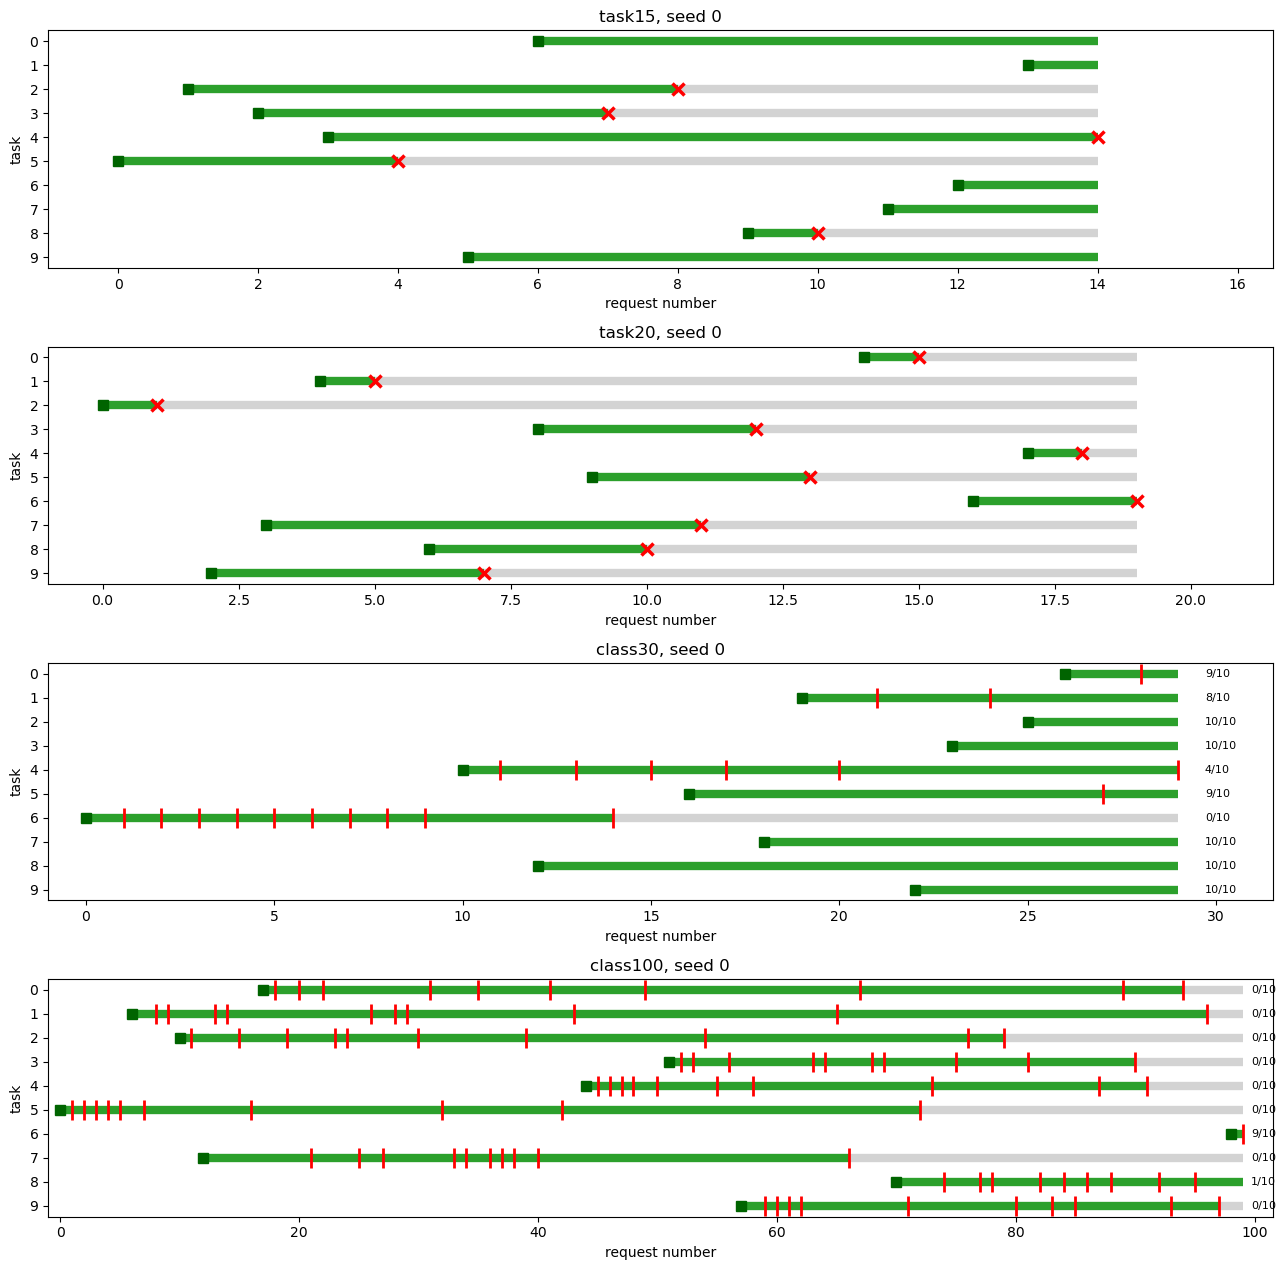

In [7]:
def plot_timeline(ax, stream, level, title):
    n = len(stream)
    learned_at = {i: pos for pos, (k, i) in enumerate(stream) if k == "L"}
    for t in range(N_TASKS):
        start = learned_at[t]
        end = n - 1
        if level == "task":
            cuts = [pos for pos, (k, i) in enumerate(stream) if k == "U" and i == t]
            gone = bool(cuts)                       # the whole task is forgotten
        else:
            cuts = [pos for pos, (k, i) in enumerate(stream) if k == "U" and task_of(i) == t]
            gone = len(cuts) == 10                  # all 10 classes forgotten
        if gone:
            end = max(cuts)
            ax.plot([end, n - 1], [t, t], color="lightgray", lw=6, solid_capstyle="butt")
        ax.plot([start, end], [t, t], color="tab:green", lw=6, solid_capstyle="butt")
        ax.plot(start, t, "s", color="darkgreen", ms=7)
        if level == "task":
            ax.plot(cuts, [t] * len(cuts), "x", color="red", ms=9, mew=2.5)
        else:
            ax.plot(cuts, [t] * len(cuts), "|", color="red", ms=14, mew=2)
            ax.text(n - 0.3, t, f"{10 - len(cuts)}/10", va="center", fontsize=8)
    ax.set(title=title, xlabel="request number", ylabel="task", yticks=range(N_TASKS), xlim=(-1, n + 1.5))
    ax.invert_yaxis()


fig, axes = plt.subplots(len(SETTINGS["standard"]), 1, figsize=(13, 3.2 * len(SETTINGS["standard"])))
for ax, (level, n) in zip(axes, SETTINGS["standard"]):
    plot_timeline(ax, saved[f"{level}{n}_seed0.json"], level, f"{level}{n}, seed 0")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "11_streams.png", dpi=120)
plt.show()

## 8. Order matters: how much learning comes after each forget?

Relapse needs **later learning**: a forgotten task can only come back if the model keeps training on other tasks afterwards. So for each `U` we count how many `L` requests come **after** it:

- many later `L`s (forgotten early) → many chances to relapse → **hard case**
- 0 later `L`s (forgotten at the very end) → no chance to relapse → easy case

A random stream mixes both. The table gives, per stream, the average and the list. When program 12 shows relapse, check whether it happens mostly for the items with many later `L`s.

                stream  avg L after U   later L's for each U, in order
     task15_seed0.json            3.4   [6, 4, 4, 3, 0]
     task15_seed1.json            3.0   [6, 4, 3, 1, 1]
     task15_seed2.json            3.8   [7, 7, 3, 2, 0]
     task20_seed0.json            3.4   [9, 6, 5, 3, 3, 3, 3, 2, 0, 0]
     task20_seed1.json            2.9   [9, 8, 7, 3, 1, 1, 0, 0, 0, 0]
     task20_seed2.json            3.2   [8, 8, 5, 3, 3, 2, 2, 1, 0, 0]
    class30_seed0.json            6.3   [9, 9, 9, 9, 9, 9, 9, 9, 9, 8, 7, 7, 7, 6, 4, 4, 2, 0, 0, 0]
    class30_seed1.json            3.6   [8, 7, 7, 7, 6, 5, 5, 3, 3, 3, 3, 3, 3, 2, 2, 2, 1, 1, 1, 1]
    class30_seed2.json            3.2   [8, 7, 7, 7, 5, 4, 4, 3, 3, 3, 3, 3, 1, 1, 1, 1, 1, 1, 1, 1]
   class100_seed0.json            3.6   [9, 9, 9, 9, 9, 8, 8, 8, 7, 6, 6, 6, 6, 5, 5, 5, 5, 5, 5, 5, ...]
   class100_seed1.json            3.8   [9, 9, 9, 9, 9, 9, 9, 9, 9, 8, 8, 8, 8, 7, 7, 7, 7, 7, 7, 7, ...]
   class100_seed2.json           

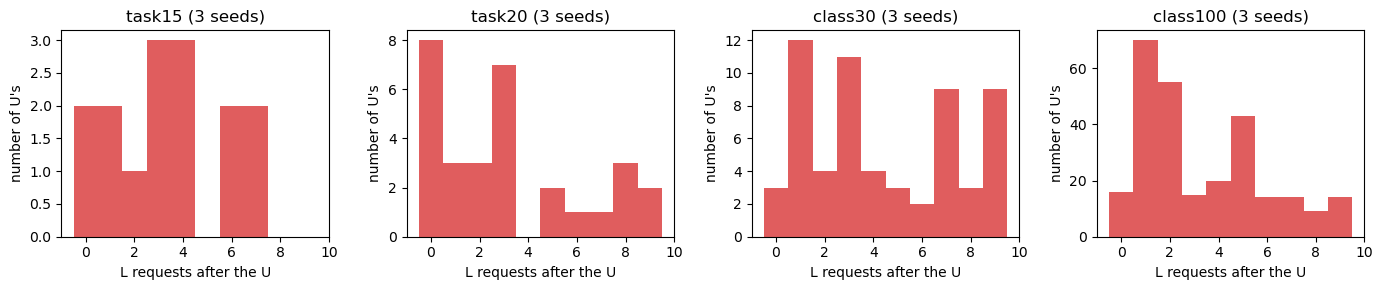

In [8]:
print(f"{'stream':>22} {'avg L after U':>14}   later L's for each U, in order")
for name, stream in saved.items():
    later = [k for _, _, k in learning_after_forget(stream)]
    shown = str(later) if len(later) <= 20 else str(later[:20])[:-1] + ", ...]"
    print(f"{name:>22} {np.mean(later):14.1f}   {shown}")

fig, axes = plt.subplots(1, len(SETTINGS["standard"]), figsize=(14, 3), sharey=False)
for ax, (level, n) in zip(axes, SETTINGS["standard"]):
    later = [k for s in SETTINGS["seeds"] for _, _, k in learning_after_forget(saved[f"{level}{n}_seed{s}.json"])]
    ax.hist(later, bins=np.arange(-0.5, N_TASKS + 0.5, 1), color="tab:red", alpha=0.75)
    ax.set(title=f"{level}{n} (3 seeds)", xlabel="L requests after the U", ylabel="number of U's")
fig.tight_layout()
plt.show()

## 9. Two hand-made streams: the worst and the best case

Random streams mix easy and hard cases. For clean experiments (programs 12 and 15) we also save two hand-made task-level streams that differ **only in order**:

- **worst case** `L0 → U0 → L1 → … → L9`: task 0 is forgotten right away, then 9 more tasks are learned (9 chances to relapse).
- **best case** `L0 → L1 → … → L9 → U0`: the same task is forgotten at the very end (no chance to relapse).

Both forget the same task and learn the same tasks. Any difference in task 0's final accuracy is caused by **order alone**: that is this program's understanding note, as an experiment.

In [9]:
handmade = {
    "handmade_worst.json": [("L", 0), ("U", 0)] + [("L", t) for t in range(1, N_TASKS)],
    "handmade_best.json": [("L", t) for t in range(N_TASKS)] + [("U", 0)],
}
for name, stream in handmade.items():
    save_stream(stream, STREAM_DIR / name, n_tasks=N_TASKS, level="task", seed=-1)   # seed -1 = hand-made
    info = load_stream(STREAM_DIR / name)
    later = learning_after_forget(info["requests"])[0][2]
    print(f"{name:>20}: {stream_to_str(info['requests'])}   ({later} L's after forgetting task 0)")

 handmade_worst.json: L0 → U0 → L1 → L2 → L3 → L4 → L5 → L6 → L7 → L8 → L9   (9 L's after forgetting task 0)
  handmade_best.json: L0 → L1 → L2 → L3 → L4 → L5 → L6 → L7 → L8 → L9 → U0   (0 L's after forgetting task 0)


## 10. Log the run

In [10]:
log_run("11_request_stream", SETTINGS,
        {"files": sorted(list(saved) + list(handmade)),
         "all_reloaded_identical": bool(all_ok),
         "avg_learn_after_forget": {name: round(float(np.mean([k for _, _, k in learning_after_forget(s)])), 2)
                                    for name, s in saved.items()}})
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## 11. Optional: change the settings

- Add `("class", 15)` to `standard`: class-level forgetting on a short stream (10 L + 5 U), the same length as `task15`. This is useful for comparing task-level and class-level forgetting at equal length.
- Change `seeds` to `[3, 4]` to add new streams. Existing files with the same name are overwritten, so don't change seeds 0–2 after program 12 has used them.
- Write your own stream: put a list like `[("L", 2), ("L", 5), ("U", 2), ("L", 7)]` through `check_stream`, then `save_stream`. For program 15 you will want streams like "forget wolf, then learn a task containing dog".

## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. Why can't a task-level stream with 10 tasks have 30 requests? What does that mean for the 30 and 100 request streams?
2. Why does rule 3 ("a forgotten item is never relearned") matter for measuring relapse?
3. In `task15_seed0`, which forgotten task has the most learning after it? Predict: which task should relapse the most in program 12?
4. In the class-level streams, some tasks lose most of their classes very early. Is that a realistic deletion pattern? What does it do to the buffer in program 12 (forgotten classes' samples get removed)?
5. The worst-case and best-case streams forget the same task. If task 0's final accuracy differs between them in program 12, what can be the only cause?